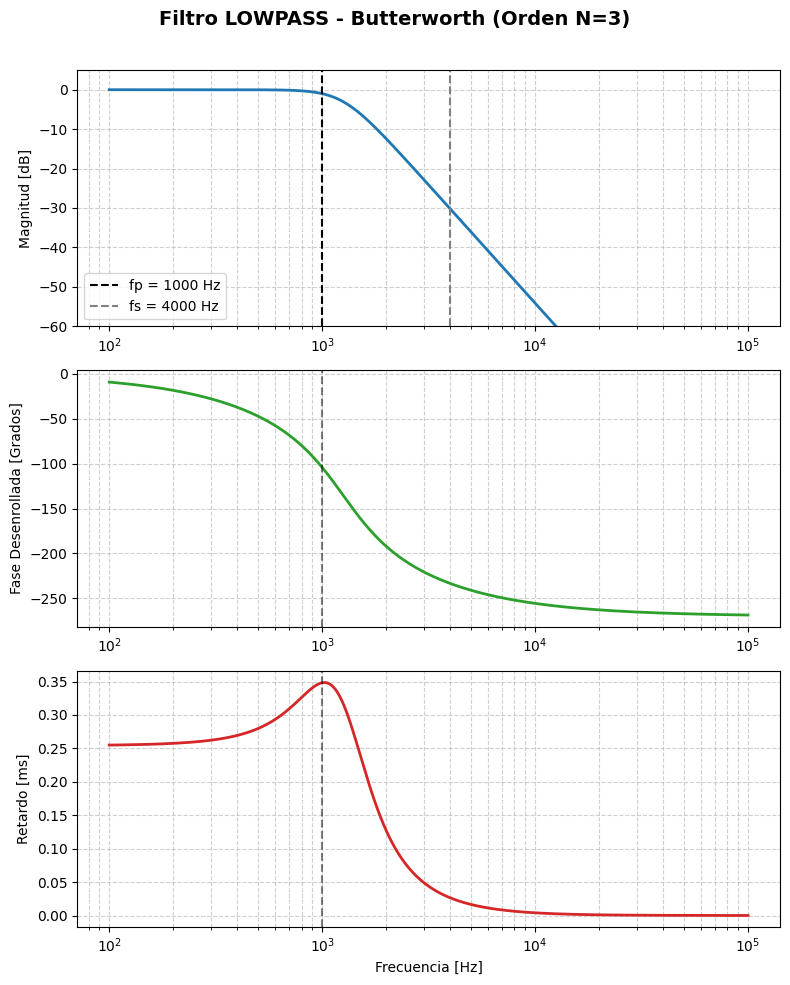

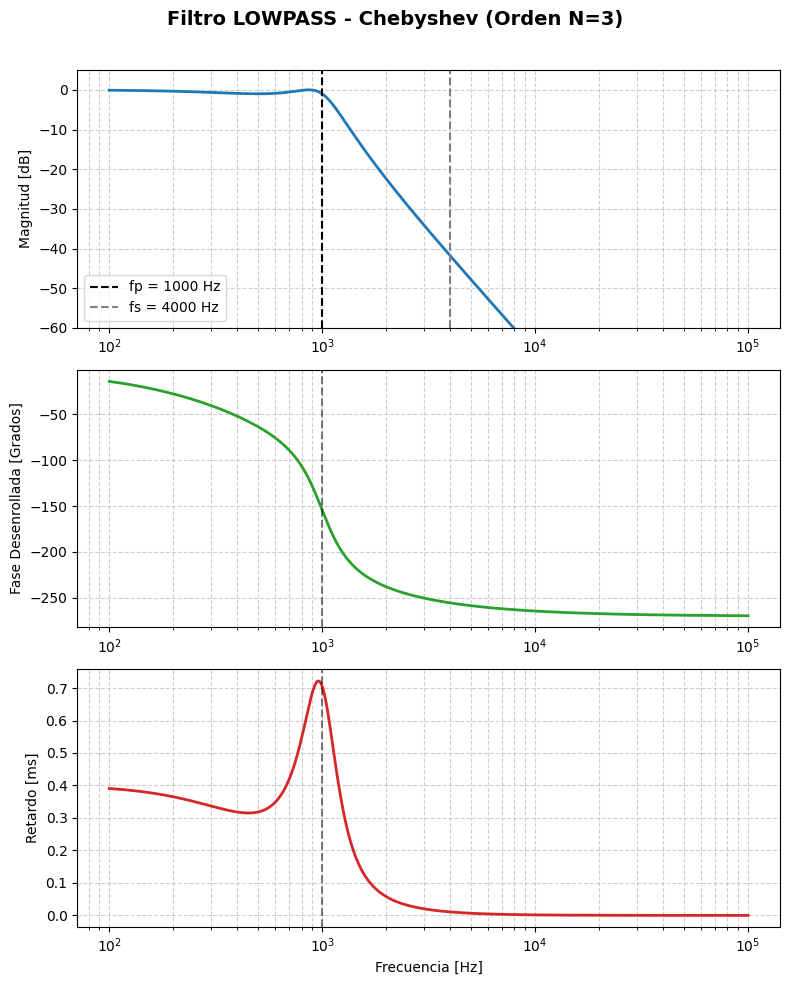

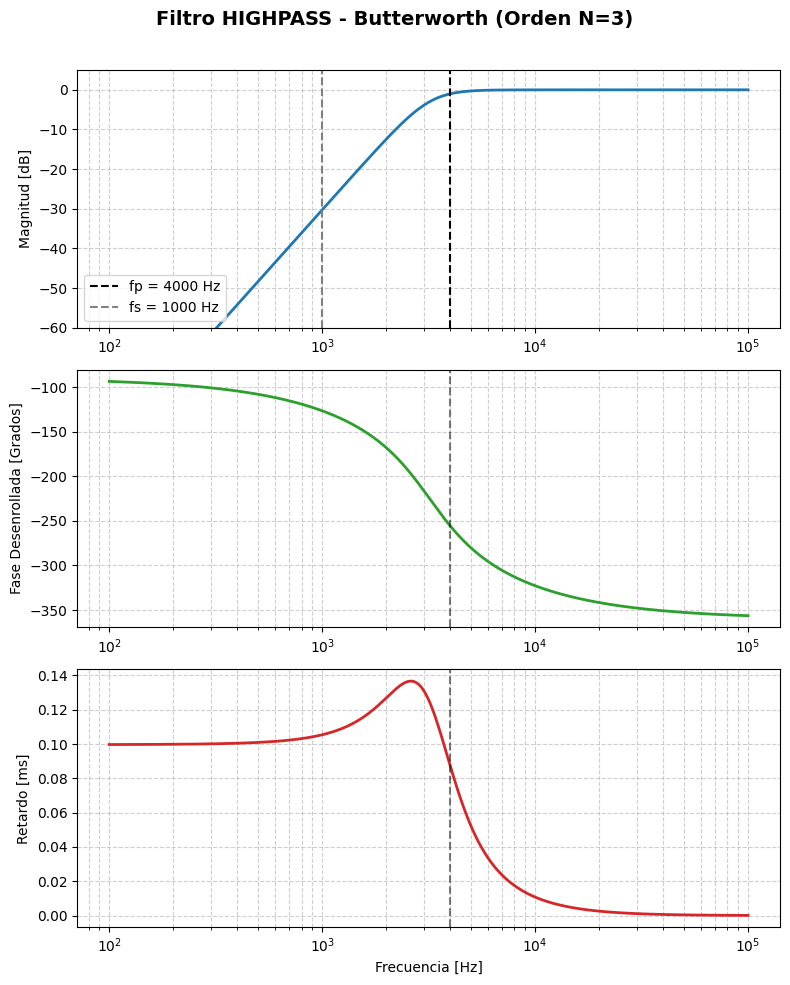

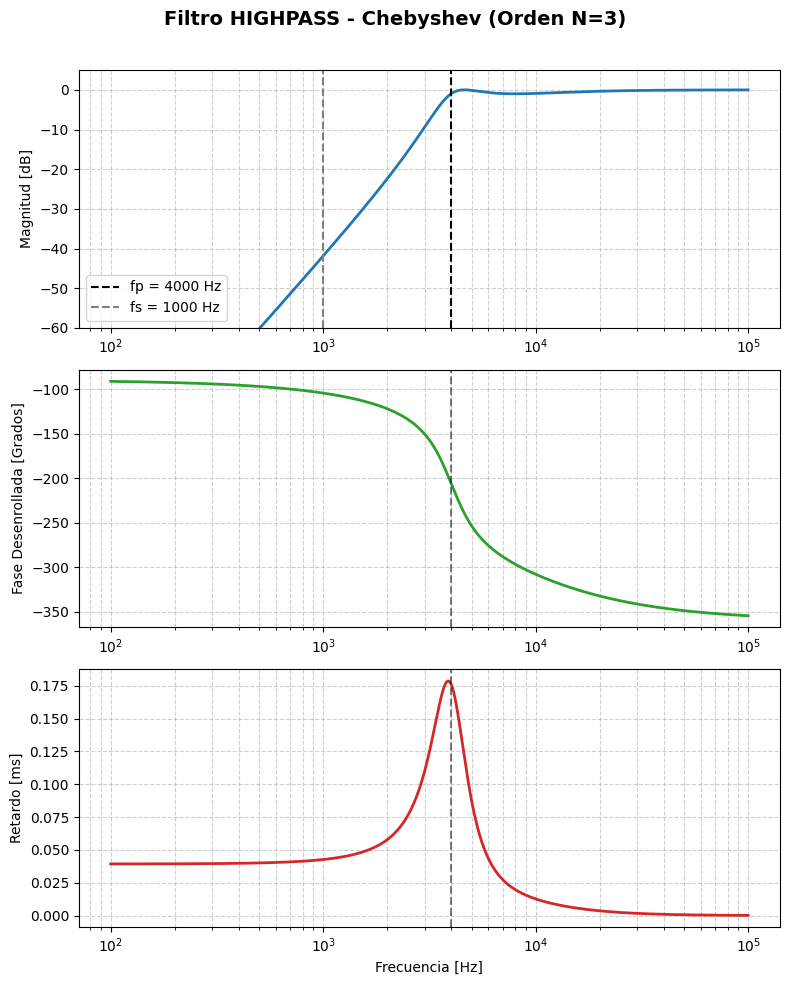

In [ ]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt

# Especificaciones de atenuación comunes
Ap = 1
As = 24

def graficar_filtro(btype, ftype, fp, fs):
    """
    Calcula y grafica la magnitud, fase y retardo de grupo para un filtro dado.
    """
    wp = 2 * np.pi * fp
    ws = 2 * np.pi * fs

    # 1. Calcular el orden (N) y la frecuencia natural (Wn)
    if ftype == 'butterworth':
        N, Wn = sig.buttord(wp, ws, Ap, As, analog=True)
        # Corrección: usamos output='ba' en lugar de 'tf'
        sys = sig.butter(N, Wn, btype=btype, analog=True, output='ba')
    elif ftype == 'chebyshev':
        N, Wn = sig.cheb1ord(wp, ws, Ap, As, analog=True)
        # Corrección: usamos output='ba' en lugar de 'tf'
        sys = sig.cheby1(N, Ap, Wn, btype=btype, analog=True, output='ba')

    # 2. Definir el vector de frecuencias para graficar (100 Hz a 100 kHz)
    f = np.logspace(2, 5, 2000)
    w = 2 * np.pi * f

    # 3. Obtener la respuesta en frecuencia
    _, h = sig.freqs(sys[0], sys[1], worN=w)

    # 4. Calcular Magnitud, Fase y Retardo de grupo
    mag = 20 * np.log10(np.abs(h))
    phase = np.unwrap(np.angle(h)) * (180 / np.pi)
    gd = -np.gradient(np.unwrap(np.angle(h)), w) * 1000  # Multiplicado por 1000 para ms

    # 5. Configurar los gráficos (3 subplots en una figura)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 10))
    titulo = f"Filtro {btype.upper()} - {ftype.capitalize()} (Orden N={N})"
    fig.suptitle(titulo, fontsize=14, fontweight='bold')

    # --- Gráfico de Magnitud ---
    ax1.semilogx(f, mag, color='#1f77b4', linewidth=2)
    ax1.axvline(fp, color='black', linestyle='--', label=f'fp = {fp} Hz')
    ax1.axvline(fs, color='gray', linestyle='--', label=f'fs = {fs} Hz')
    ax1.set_ylabel('Magnitud [dB]')
    ax1.set_ylim(-60, 5)
    ax1.grid(True, which="both", ls="--", alpha=0.6)
    ax1.legend(loc='lower left')

    # --- Gráfico de Fase ---
    ax2.semilogx(f, phase, color='#2ca02c', linewidth=2)
    ax2.axvline(fp, color='black', linestyle='--', alpha=0.5)
    ax2.set_ylabel('Fase Desenrollada [Grados]')
    ax2.grid(True, which="both", ls="--", alpha=0.6)

    # --- Gráfico de Retardo de Grupo ---
    ax3.semilogx(f, gd, color='#d62728', linewidth=2)
    ax3.axvline(fp, color='black', linestyle='--', alpha=0.5)
    ax3.set_xlabel('Frecuencia [Hz]')
    ax3.set_ylabel('Retardo [ms]')
    ax3.grid(True, which="both", ls="--", alpha=0.6)

    plt.tight_layout()
    plt.subplots_adjust(top=0.92) # Ajuste para el título general
    plt.show()

# ==========================================
# Generación de los 4 gráficos solicitados
# ==========================================

# Caso 1: Pasabajos Butterworth
graficar_filtro('lowpass', 'butterworth', fp=1000, fs=4000)

# Caso 2: Pasabajos Chebyshev
graficar_filtro('lowpass', 'chebyshev', fp=1000, fs=4000)

# Caso 3: Pasaaltos Butterworth
graficar_filtro('highpass', 'butterworth', fp=4000, fs=1000)

# Caso 4: Pasaaltos Chebyshev
graficar_filtro('highpass', 'chebyshev', fp=4000, fs=1000)